# Displaying 2-dimensional fields with Makie
Displaying 2D fields, such as the sea surface temperature or the bathymetry, is a common task in ocean data visualisation. We present 2 main techniques (`heatmap` and `surface`) and detail how to improve the resulting maps.

## The packages
We will rely essentialy on the plotting library [Makie](https://makie.org/website/).        
Additionaly we will load [NCDatasets](https://github.com/JuliaGeo/NCDatasets.jl) to load some data.        

There are several backends. For instance:
- if you want to work OpenGL, then you need to load `GLMakie`
- if you want to render 2D by Cairo Graphics, you will use `CairoMakie`.

In [1]:
using Pkg
Pkg.activate("../")
Pkg.instantiate()
using Makie
using CairoMakie
using NCDatasets
using JupyterFormatter
enable_autoformat()

  Activating project at `~/Projects/maps-with-makie`
┌ Warning: The project dependencies or compat requirements have changed since the manifest was last resolved.
│ It is recommended to `Pkg.resolve()` or consider `Pkg.update()` if necessary.
└ @ Pkg.API ~/.julia/juliaup/julia-1.13.2+0.x64.linux.gnu/share/julia/stdlib/v1.13/Pkg/src/API.jl:1312
Precompiling packages...
   2.5 s  ✓ libaom_jll
   2.7 s  ✓ Expat_jll
   3.0 s  ✓ s2n_tls_jll
   3.2 s  ✓ FriBidi_jll
   3.2 s  ✓ Libuuid_jll
   3.5 s  ✓ Libmount_jll
   3.4 s  ✓ FreeType2_jll
   4.2 s  ✓ CommonDataModel
   4.3 s  ✓ libzip_jll
   2.8 s  ✓ IntervalArithmetic → IntervalArithmeticIrrationalConstantsExt
   4.0 s  ✓ OpenEXR_jll
   3.9 s  ✓ Xorg_libX11_jll
   4.1 s  ✓ MPICH_jll
   3.5 s  ✓ FreeType
   4.1 s  ✓ aws_c_io_jll
   5.3 s  ✓ Glib_jll
   5.6 s  ✓ Fontconfig_jll
   3.0 s  ✓ Xorg_libXrender_jll
   3.3 s  ✓ aws_c_http_jll
   3.9 s  ✓ Xorg_libXfixes_jll
   3.8 s  ✓ Xorg_libXext_jll
   4.6 s  ✓ OpenEXR
  11.2 s  ✓ Roots
   9.6 s  ✓

   4.6 s  ✓ Xorg_libXext_jll
   5.6 s  ✓ Fontconfig_jll
   5.3 s  ✓ OpenEXR
  12.4 s  ✓ Roots
  12.9 s  ✓ SpecialFunctions
   3.7 s  ✓ libva_jll
   3.9 s  ✓ Libglvnd_jll
   4.5 s  ✓ Cairo_jll
   2.3 s  ✓ Roots → RootsChainRulesCoreExt
   2.4 s  ✓ Roots → RootsUnitfulExt
   2.3 s  ✓ ColorVectorSpace → SpecialFunctionsExt
   4.4 s  ✓ StatsFuns
   4.4 s  ✓ SpecialFunctions → SpecialFunctionsChainRulesCoreExt
   3.8 s  ✓ libwebp_jll
   4.0 s  ✓ HarfBuzz_jll
   1.6 s  ✓ StatsFuns → StatsFunsInverseFunctionsExt
   4.0 s  ✓ StatsFuns → StatsFunsChainRulesCoreExt
   3.9 s  ✓ libass_jll
   5.8 s  ✓ WebP
  24.8 s  ✓ JSON
  24.9 s  ✓ StaticArrays
   2.8 s  ✓ StaticArrays → StaticArraysChainRulesCoreExt
   3.3 s  ✓ Accessors → StaticArraysExt
   3.8 s  ✓ StaticArrays → StaticArraysStatisticsExt
   3.8 s  ✓ ConstructionBase → ConstructionBaseStaticArraysExt
   4.0 s  ✓ FillArrays → FillArraysStaticArraysExt
   4.1 s  ✓ Adapt → AdaptStaticArraysExt
   4.4 s  ✓ StructArrays → StructArraysStaticArrays

1-element Vector{Function}:
 format_current_cell (generic function with 1 method)

In [2]:
using Pkg
Pkg.activate("../")
Pkg.status()

  Activating 

Status `~/Projects/maps-with-makie/Project.toml`


project at `~/Projects/maps-with-makie`


  [c9ce4bd3] ArchGDAL v0.10.12
⌃ [13f3f980] CairoMakie v0.15.15
  [35d6a980] ColorSchemes v3.31.0
  [0703355e] DimensionalData v0.30.2
  [411431e0] Extents v0.1.6
  [68eda718] GeoFormatTypes v0.4.5
⌃ [db073c08] GeoMakie v0.7.17
  [7073ff75] IJulia v1.34.4
  [916415d5] Images v0.26.2
  [b964fa9f] LaTeXStrings v1.4.1
⌅ [ee78f7c6] Makie v0.24.15 ⚲
  [fea52e5a] MapTiles v1.0.2
  [f57f5aa1] PNGFiles v0.4.5
  [c94c279d] Proj v1.9.0
  [a3a2b9e3] Rasters v0.15.0
  [263fe934] TileProviders v0.1.4
  [f43a241f] Downloads v1.7.0
Info Packages marked with ⌃ and ⌅ have new versions available. Those with ⌃ may be upgradable, but those with ⌅ are restricted by compatibility constraints from upgrading. To see why use `status --outdated`


## Data
We will load the GEBCO bathymetry.

In [33]:
datadir = "../data/"
figdir = "../figures/resolution/"
mkpath(figdir)
datafile = joinpath(datadir, "gebco_30sec_16.nc")

if isfile(datafile)
    @info("File already downloaded")
else
    download("https://dox.uliege.be/index.php/s/U0pqyXhcQrXjEUX/download", datafile)
end

[ Info: File already downloaded


In order to slightly reduce the matrix size, we will sub-sample the data with a factor NN.

In [3]:
NN = 4
ds = NCDataset(datafile)
lon = ds["lon"][1:NN:end]
lat = ds["lat"][1:NN:end]
bathy = ds["bat"][1:NN:end, 1:NN:end]
close(ds)
@info(size(bathy));

[ Info: (675, 338)


## 1st method: Heatmap
In Makie, `heatmap` is the equivalent of `pcolor` in other languages.

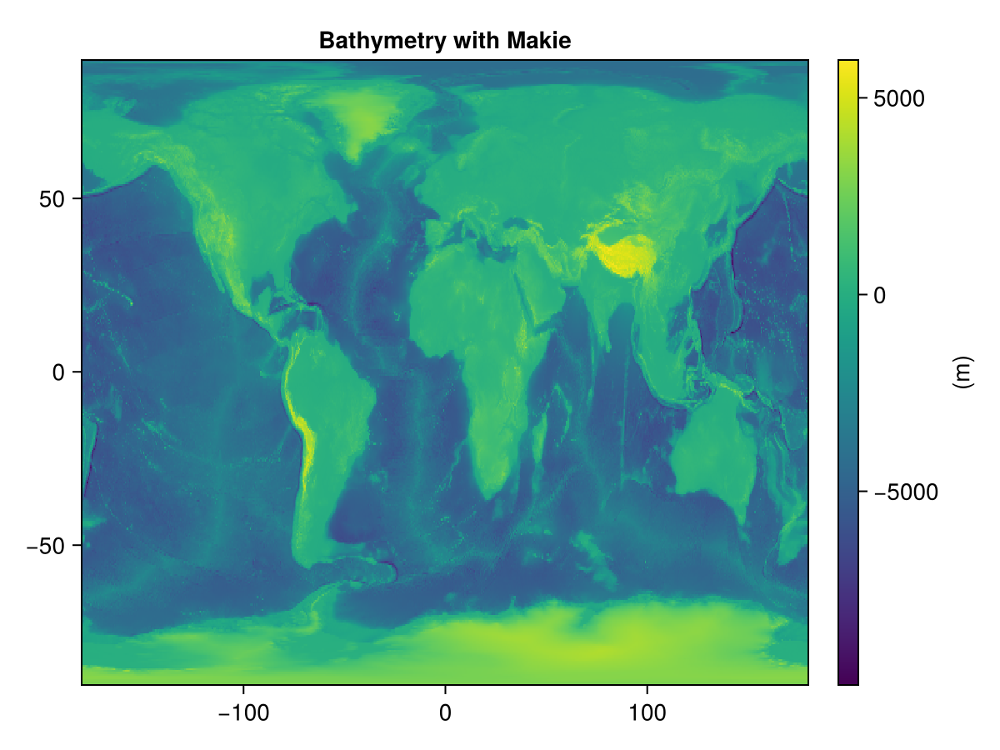

In [4]:
f = Figure()
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy)
Colorbar(f[1, 2], hm, label = "(m)")
f

Let's detail all the operations:
- `f` is the figure object;
- `ax` is the Axis, which can contain many options;
- `heatmap!` is the function that generate the plot;

### What can be improved?
The result obtained with the default settings is always something we can improve.
1. The coastline: it can be simply added as the contour where the bathymetry is equal to zero.
2. The colormap: we will select one from [ColorSchemes](https://docs.juliaplots.org/dev/generated/colorschemes/)
3. The color range: the values are computed from the data, but we can set them _by hand_;
. The x and ytickslabels: they should have the ° symbol.
5. The colorbar label: it can be left unrotated (i.e., horizontal).

### Change the colormap
The default colormap proposed by `Makie` is not the best option for the bathymetry.      
Here we prefer to use the `delta` colormap, a divergent colormap suitable for this variable.

In [5]:
using ColorSchemes
topocmap = ColorSchemes.delta

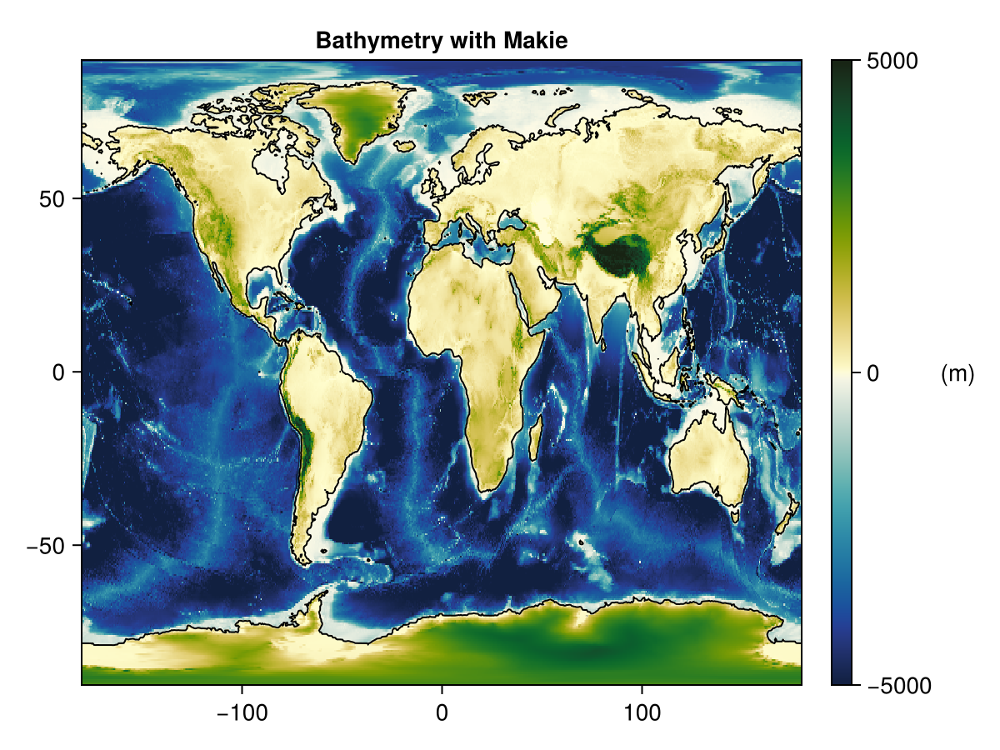

In [16]:
f = Figure()
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap, colorrange = [-5000, 5000])
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(f[1, 2], hm, label = "(m)", labelrotation = 0)
f

### Use non-symmetric values for lower and upper bound
In the previous map we set symmetric limits around zero (-5000 m and 5000 m) in order to have the ocean in blue tones and the land in yellow/green. 

If one needs to set non-symmetric values (for instance -6000 m and 8000 m), it is necessary to create a custom colormap.

In [7]:
lower = -6000.0
upper = 8000.0
zp = -lower / (upper - lower)
cmap = cgrad(:delta)

n = 512
ts = range(0, 1; length = n)
topocmap2 = [t <= zp ? cmap[0.5*t/zp] : cmap[0.5+0.5*(t-zp)/(1-zp)] for t in ts]

We can see that the zero is not in the center anymore.

The resulting map is as follows:

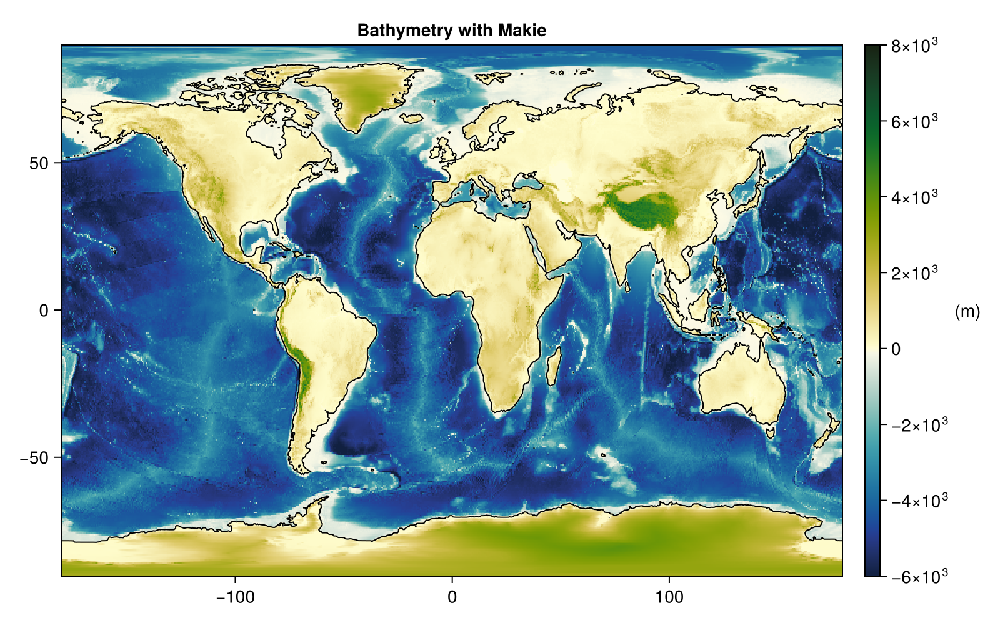

In [8]:
f = Figure()
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(f[1, 2], hm, label = "(m)", labelrotation = 0)
f

Meanwhile, a new issue has come up: the colorbar tick labels are now written with exponents.     
This is solved by speficying the `tickformat`:

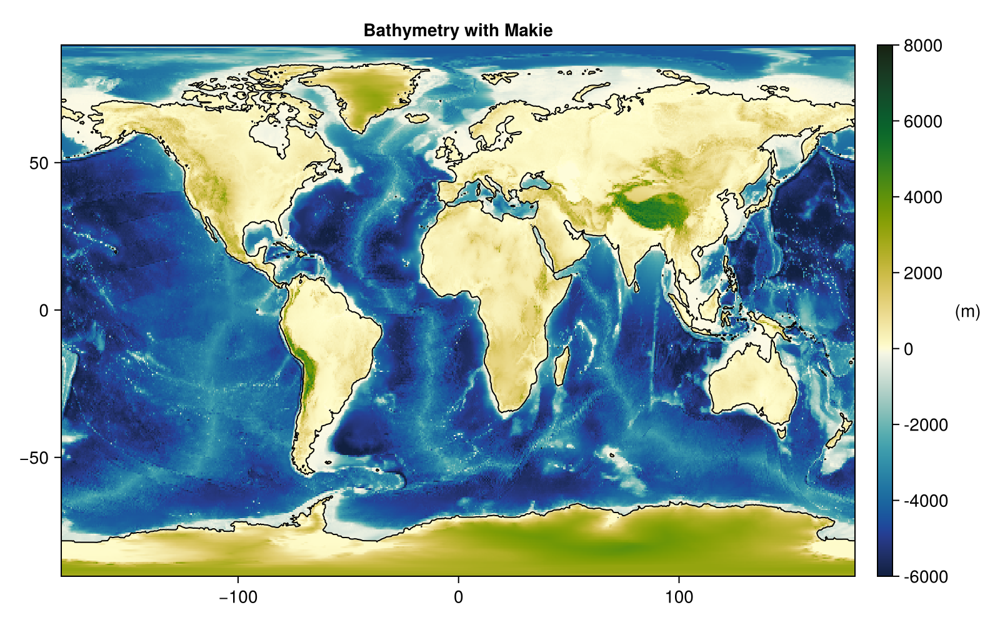

In [9]:
f = Figure()
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

### Styling the grid
We create a dictionary storing the differents 

In [10]:
gridoptions = Dict(
    :xgridstyle => :dash,
    :ygridstyle => :dash,
    :xgridcolor => :gray70,
    :ygridcolor => :gray70,
    :xticks => -180:30:180,
    :yticks => -90:30:90,
    :titlesize => 20,
)

Dict{Symbol, Any} with 7 entries:
  :ygridcolor => :gray70
  :titlesize  => 20
  :xgridstyle => :dash
  :ygridstyle => :dash
  :xgridcolor => :gray70
  :xticks     => -180:30:180
  :yticks     => -90:30:90

### Adding the ° symbol in the xticklabels and yticklabels
We create 2 simple functions to properly format the labels.

In [11]:
function degformat(pos, neg)
    function (values)
        map(values) do v
            isapprox(v, 0; atol = 1e-8) && return "0°"
            a = round(abs(v); digits = 2)
            s = isinteger(a) ? string(Int(a)) : string(a)
            string(s, "°", v > 0 ? pos : neg)
        end
    end
end

getlonformat = degformat("E", "W")
getlatformat = degformat("N", "S")

#degformat##0 (generic function with 1 method)

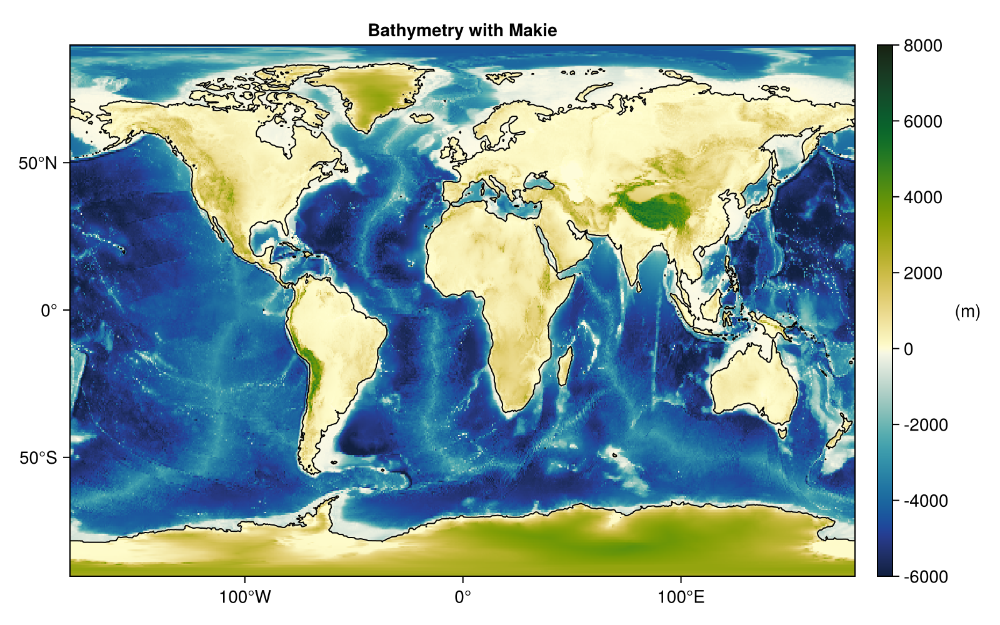

In [12]:
f = Figure()
ax = Axis(
    f[1, 1],
    title = "Bathymetry with Makie",
    xtickformat = getlonformat,
    ytickformat = getlatformat,
)
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])

contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

## 2° method: surface
The function [`surface`](https://docs.makie.org/dev/reference/plots/surface) is fundamentally designed to display 3D mesh plot, but it can also be used to display 2D data. 

The main reason to use `surface` is that it allows one to work with curvilinear coordinates, i.e., using coordinates that are matrices, and not vectors.

The following options have to be set:    
- `shading=NoShading`
- `interpolate=false`

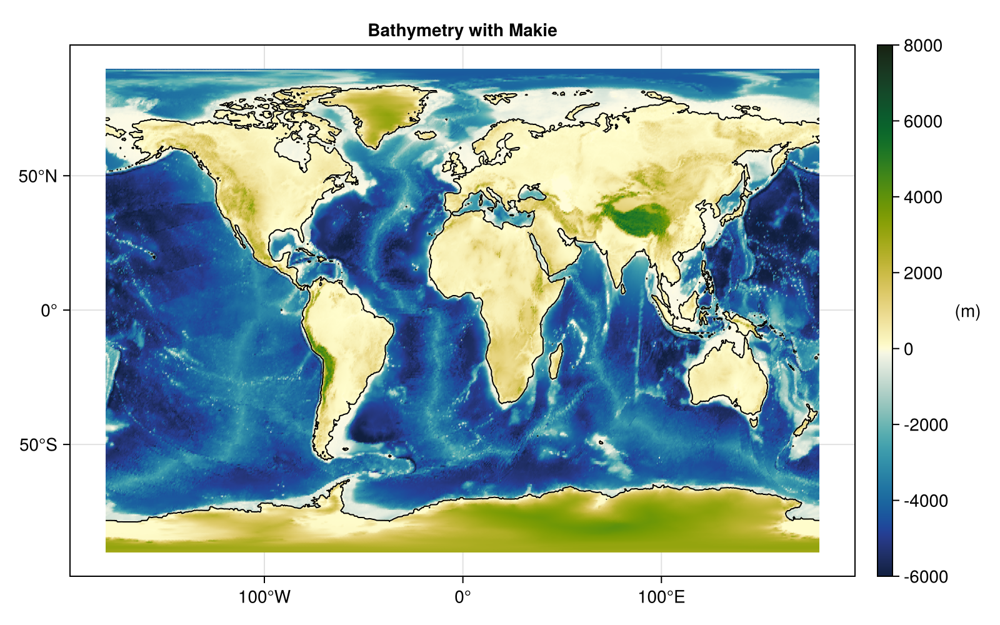

In [13]:
f = Figure()
ax = Axis(
    f[1, 1],
    title = "Bathymetry with Makie",
    xtickformat = getlonformat,
    ytickformat = getlatformat,
)
hm = surface!(
    ax,
    lon,
    lat,
    bathy,
    colormap = topocmap2,
    colorrange = [lower, upper],
    shading = NoShading,
    interpolate = false,
)
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

A white band around the plot is now visible, we can remove it by specifying the map boundary         
(through the `limits` argument in the `Axis` object):

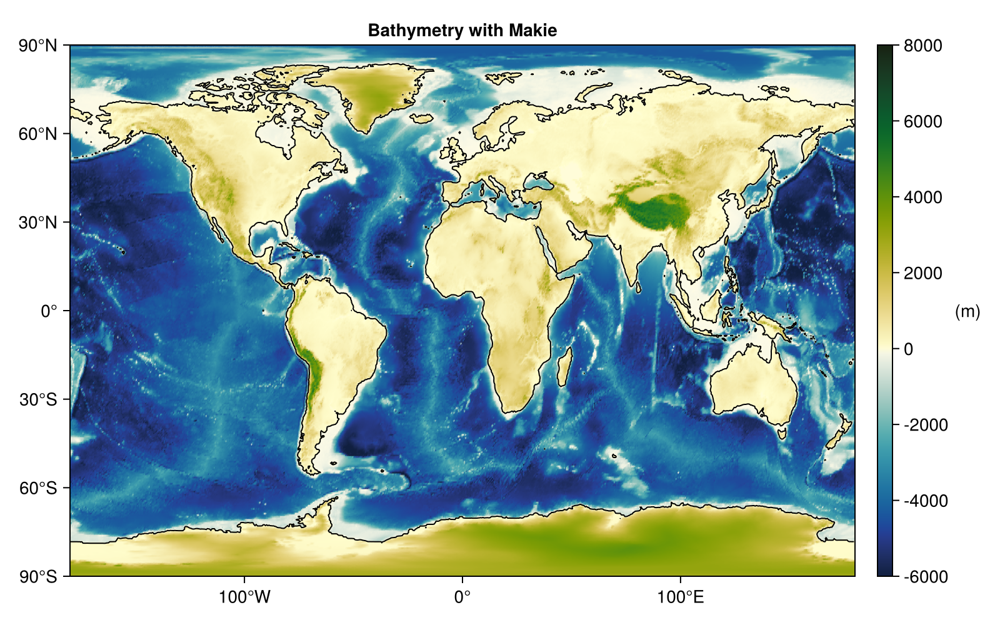

In [14]:
f = Figure(size = (800, 500))
ax = Axis(
    f[1, 1],
    title = "Bathymetry with Makie",
    limits = (-180, 180, -90, 90),
    xtickformat = getlonformat,
    ytickformat = getlatformat,
)
hm = surface!(
    ax,
    lon,
    lat,
    bathy,
    colormap = topocmap2,
    colorrange = [lower, upper],
    shading = NoShading,
    interpolate = false,
)
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

## Saving figures locally
Once we are happy with the final result, it can be saved as a local file using the command [`save`](https://docs.makie.org/stable/api#FileIO.save-Tuple{String,%20Union{Figure,%20Makie.FigureAxisPlot,%20Scene}}).     
Let's create a function to create the final plot.

In [37]:
function make_final_map(; figsize::Tuple{Int64,Int64} = (400, 300))
    f = Figure(size = figsize)
    ax = Axis(
        f[1, 1],
        title = "Bathymetry with Makie",
        xtickformat = getlonformat,
        ytickformat = getlatformat,
    )
    hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])

    contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
    Colorbar(
        f[1, 2],
        hm,
        label = "(m)",
        labelrotation = 0,
        tickformat = values -> [string(round(Int, v)) for v in values],
    )
    return f::Figure
end

make_final_map (generic function with 2 methods)

### Changing the resolution
Now we create different figures by changing the figure size:

In [48]:
f = make_final_map();
save(joinpath(figdir, "map_400_300.png"), f)
f = make_final_map(figsize = (800, 600));
save(joinpath(figdir, "map_800_600.png"), f)
f = make_final_map(figsize = (1200, 900));
save(joinpath(figdir, "map_1200_900.png"), f)

Increasing the figure size argument creates layer images (in pixels). 

### Changing the format
One can also save the figure as vector graphics (SVG, PDF, and EPS).     
Note that even with these formats, the figure size has an influence of the resulting figure.

In [51]:
f = make_final_map(figsize = (1200, 900));
save(joinpath(figdir, "map_1200_900.pdf"), f)

CairoMakie.Screen{PDF}
